In [5]:
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import missingno as msno
from plotly.subplots import make_subplots



In [ ]:
df_train = pd.read_csv("data/Train.csv")
df_train.shape

In [3]:
# Bereinigten DataFrame erstellen (siehe 04_eda_justus.ipynb für die Begründung)

df_clean = df_train.copy()

# 1. Windspalten -> Windgeschwindigkeit (sqrt(u^2 + v^2))
df_clean["wind_speed"] = np.sqrt(
    df_clean["u_component_of_wind_10m_above_ground"]**2
    + df_clean["v_component_of_wind_10m_above_ground"]**2
)
df_clean = df_clean.drop(columns=[
    "u_component_of_wind_10m_above_ground",
    "v_component_of_wind_10m_above_ground",
])

# 2. Winkel-Spalten (sensor/solar azimuth/zenith) nur einmal behalten
# -> alle Gasgruppen teilen sich denselben physikalischen Winkel (gleicher Überflug),
#    daher aus der Gruppe mit den wenigsten NaNs behalten: L3_AER_AI (nur 197 von 30557 fehlend)
angle_suffixes = [
    "sensor_azimuth_angle",
    "sensor_zenith_angle",
    "solar_azimuth_angle",
    "solar_zenith_angle",
]
keep_group = "L3_AER_AI"

angle_cols_all = [c for c in df_clean.columns if c.endswith(tuple(angle_suffixes))]
angle_cols_keep = [f"{keep_group}_{suffix}" for suffix in angle_suffixes]
angle_cols_drop = [c for c in angle_cols_all if c not in angle_cols_keep]

df_clean = df_clean.drop(columns=angle_cols_drop)
df_clean = df_clean.rename(columns={
    f"{keep_group}_{suffix}": suffix for suffix in angle_suffixes
})

# 3. "_slant_column_number_density"-Spalten droppen (AMF-korrigierte "vertical"-Variante behalten)
slant_cols = [c for c in df_clean.columns if "slant_column_number_density" in c]
df_clean = df_clean.drop(columns=slant_cols)

# 4. CH4-Spalten droppen (>80% NaN)
ch4_cols = [c for c in df_clean.columns if c.startswith("L3_CH4")]
df_clean = df_clean.drop(columns=ch4_cols)

print(f"Spalten vorher: {df_train.shape[1]}, Spalten nachher: {df_clean.shape[1]}")
df_clean.info()

Spalten vorher: 82, Spalten nachher: 47
<class 'pandas.DataFrame'>
RangeIndex: 30557 entries, 0 to 30556
Data columns (total 47 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Place_ID X Date                                      30557 non-null  str    
 1   Date                                                 30557 non-null  str    
 2   Place_ID                                             30557 non-null  str    
 3   target                                               30557 non-null  float64
 4   target_min                                           30557 non-null  float64
 5   target_max                                           30557 non-null  float64
 6   target_variance                                      30557 non-null  float64
 7   target_count                                         30557 non-null  int64  
 8   precipitable_water_entire_atmosphere 

<Axes: >

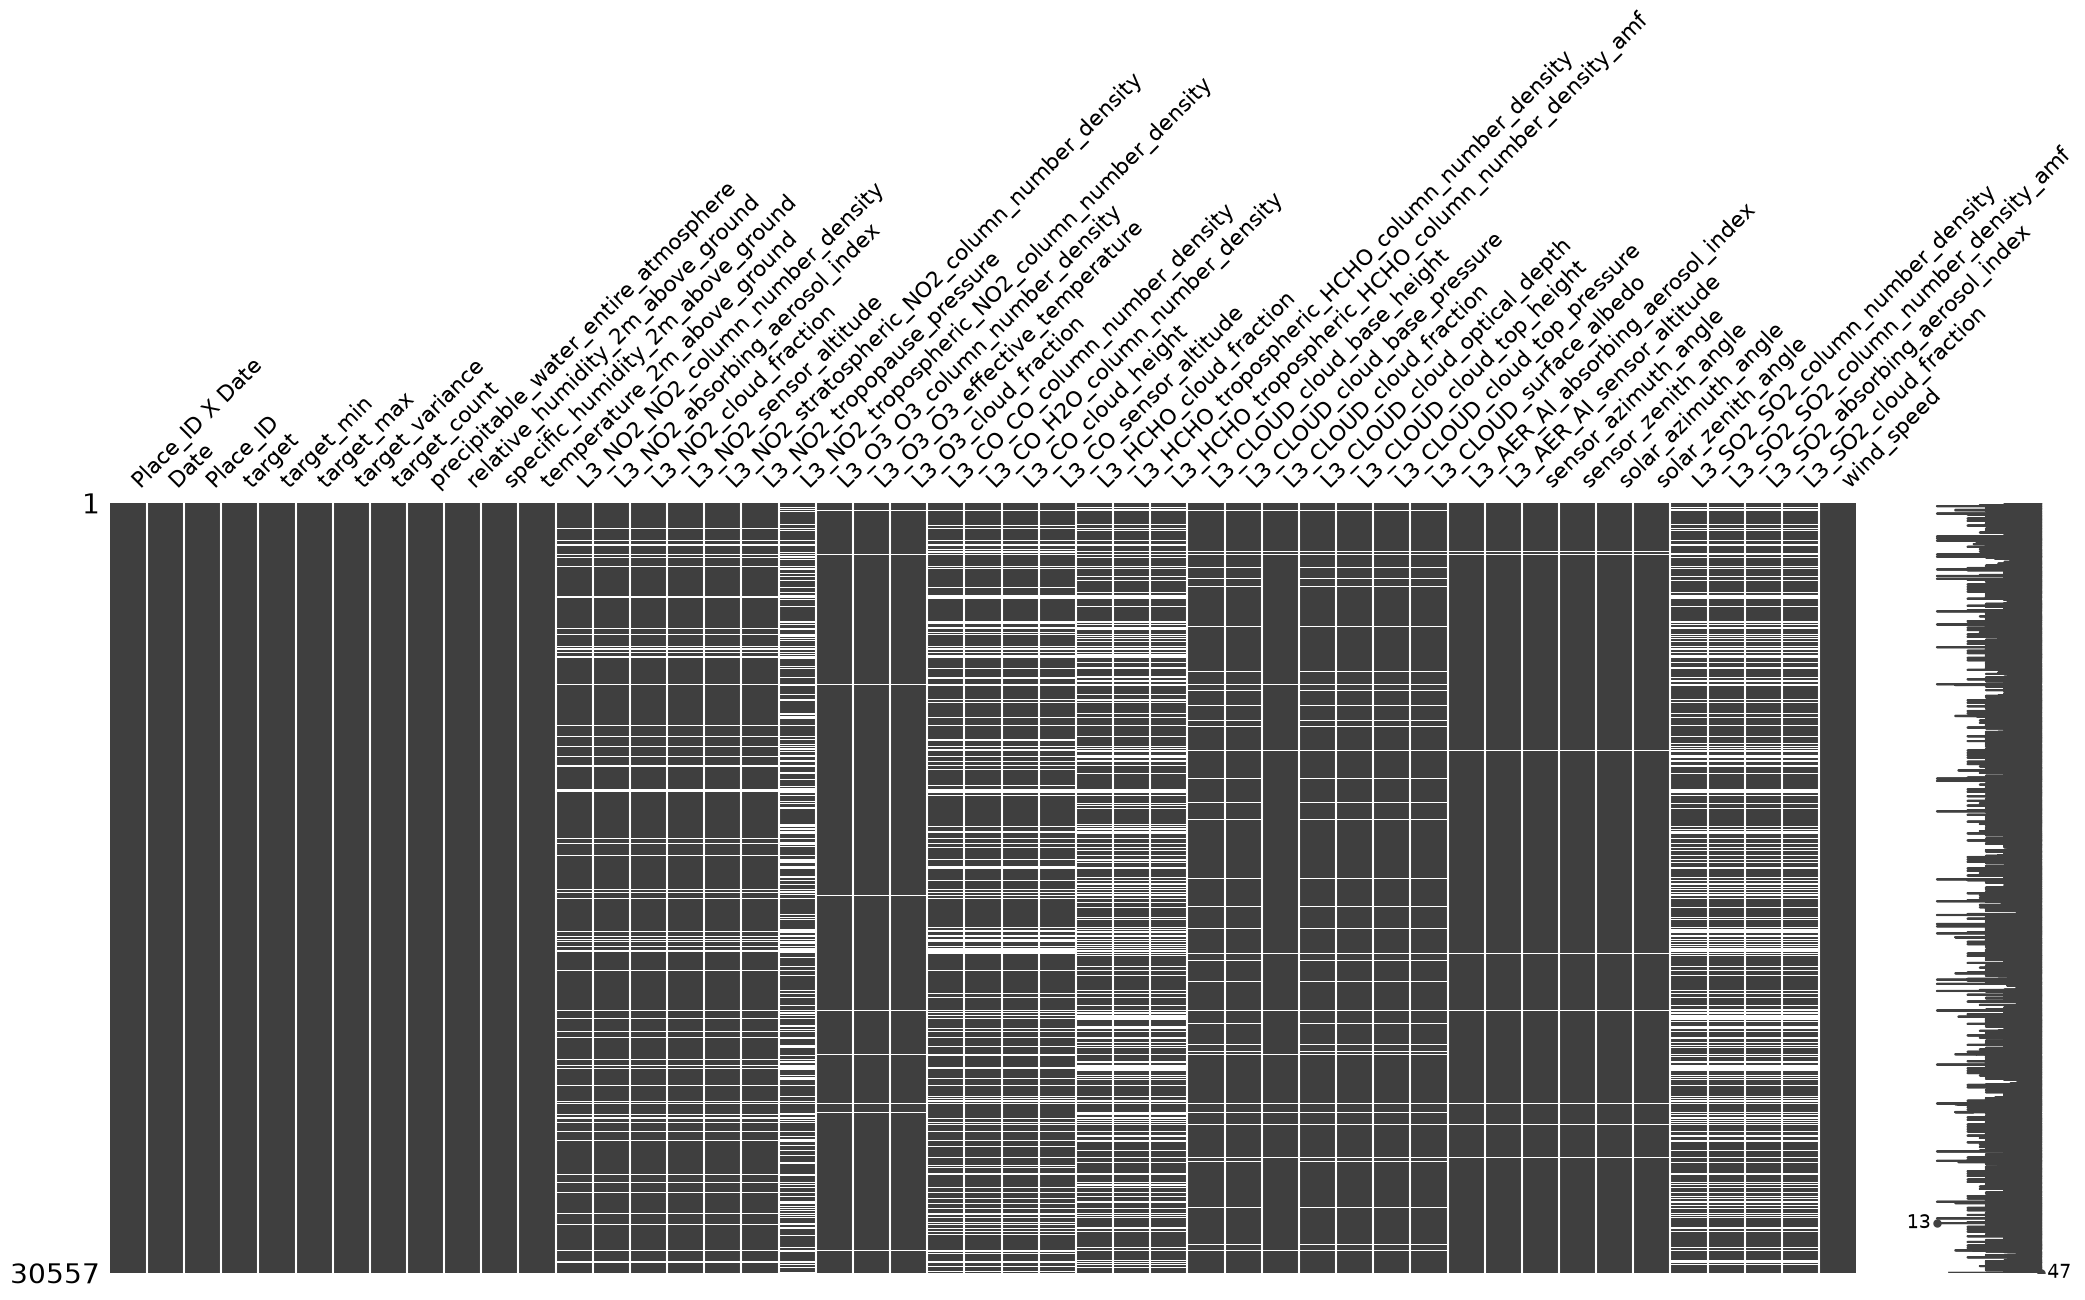

In [7]:
msno.matrix(df_clean)

In [8]:
df_clean["target_count"]

0        92
1        91
2        96
3        96
4        95
         ..
30552    72
30553    72
30554    72
30555    72
30556    72
Name: target_count, Length: 30557, dtype: int64

In [9]:
df_clean["target_count"].unique()

array([  92,   91,   96,   95,   94,   93,   85,   72,   90,   69,   81,
         80,   86,   70,   71,   82,   77,   73,   83,   55,   79,   23,
         24,   21,   22,   19,    9,   17,   11,   12,   20,   18,   64,
         33,   66,   58,   51,   48,   44,   39,   34,   67,   68,    7,
         32,   60,   40,   36,   52,   42,   38,   50,   26,   87,   76,
         63,   84,   74,   62,   59,   53,   75,   78,   89,   88,  120,
        119,  126,  142,  144,  143,  140,  141,   46,  134,  139,  138,
        130,  129,  128,  132,   47,   35,   28,   14,   41,   43,   37,
        186,  188,  182,  180,  162,  179,  189,  174,  163,  158,  190,
        187,  177,  168,  184,  160,  146,  176,  185,  166,  183,  191,
        101,  157,  171,  192,  149,  135,  175,  172,  167,  548,  571,
        531,  491,  520,  578,  576,  496,  562,  585,  587,  586,  560,
        533,  444,  489,  451,  485,  452,  484,  559,  441,  433,  486,
        376,  454,  511,  572,  540,  498,  517,  5

In [4]:
# Als CSV speichern
df_clean.to_csv("data/train_clean.csv", index=False)
print("Gespeichert unter data/train_clean.csv")

Gespeichert unter data/train_clean.csv


## Imputation: zeitliche Interpolation (Luecke < 3 Tage) + Orts-Median als Fallback

Strategie:
1. Pro Ort (`Place_ID`) zeitbasiert interpolieren (`method="time"`, respektiert echte Kalenderabstaende, auch wenn einzelne Kalendertage als ganze Zeile fehlen) - aber NUR wenn die Luecke zwischen zwei vorhandenen Messungen kleiner als 3 Tage ist (also 1-2 fehlende Tage dazwischen).
2. Alles, was danach noch fehlt (Luecke >= 3 Tage, oder Rand-Luecken vor der ersten/nach der letzten Messung eines Ortes), wird mit dem **Median dieses Ortes** aufgefuellt.
3. Letzter Rueckfall: falls eine Spalte fuer einen Ort komplett fehlt (Orts-Median selbst ist NaN), globaler Median ueber alle Orte.


In [ ]:
# Gap-aware zeitliche Interpolation (nur Luecken < 3 Tage) je Ort

df_imputed = df_clean.copy()
df_imputed["Date"] = pd.to_datetime(df_imputed["Date"])
df_imputed = df_imputed.sort_values(["Place_ID", "Date"]).reset_index(drop=True)

cols_to_impute = df_imputed.columns[df_imputed.isna().any()].tolist()
print(f"{len(cols_to_impute)} Spalten mit fehlenden Werten:")
print(cols_to_impute)

MAX_GAP_DAYS = 2  # "Luecke < 3 Tage" -> 1 oder 2 fehlende Tage dazwischen werden interpoliert


def interpolate_short_gaps(group_df, col, max_gap_days=MAX_GAP_DAYS):
    s = group_df.set_index("Date")[col].sort_index()

    valid_dates = s.dropna().index
    if len(valid_dates) == 0:
        return s.values  # ganze Spalte fuer diesen Ort fehlt -> Median-Fallback uebernimmt spaeter

    date_lookup = pd.Series(valid_dates, index=valid_dates)
    prev_valid = date_lookup.reindex(s.index, method="ffill")
    next_valid = date_lookup.reindex(s.index, method="bfill")
    gap_days = (next_valid - prev_valid).dt.days

    s_interp = s.interpolate(method="time", limit_area="inside")

    is_na = s.isna()
    fill_mask = is_na & prev_valid.notna() & next_valid.notna() & (gap_days <= max_gap_days)

    result = s.copy()
    result[fill_mask] = s_interp[fill_mask]
    return result.values


n_before = df_imputed[cols_to_impute].isna().sum().sum()

for col in cols_to_impute:
    parts = []
    for place_id, group in df_imputed.groupby("Place_ID", sort=False):
        parts.append(pd.Series(interpolate_short_gaps(group, col), index=group.index))
    df_imputed[col] = pd.concat(parts).sort_index()

n_after_interp = df_imputed[cols_to_impute].isna().sum().sum()
print(f"NaNs vor Interpolation: {n_before}")
print(f"NaNs nach Interpolation (Luecken < 3 Tage gefuellt): {n_after_interp} "
      f"({(n_before - n_after_interp) / n_before:.1%} durch Interpolation gefuellt)")


In [ ]:
# Verbleibende Luecken (>= 3 Tage, Rand-Luecken) mit Orts-Median auffuellen,
# letzter Rueckfall: globaler Median

for col in cols_to_impute:
    df_imputed[col] = df_imputed[col].fillna(df_imputed.groupby("Place_ID")[col].transform("median"))

n_after_median = df_imputed[cols_to_impute].isna().sum().sum()
print(f"NaNs nach Orts-Median-Fallback: {n_after_median}")

for col in cols_to_impute:
    df_imputed[col] = df_imputed[col].fillna(df_imputed[col].median())

n_final = df_imputed[cols_to_impute].isna().sum().sum()
print(f"NaNs final: {n_final}")

df_imputed.to_csv("data/train_imputed.csv", index=False)
print("Gespeichert unter data/train_imputed.csv")
